Cloning into 'mm-bem'...
remote: Enumerating objects: 356, done.
remote: Counting objects: 100% (356/356), done.
remote: Compressing objects: 100% (351/351), done.
remote: Total 356 (delta 167), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (356/356), 12.68 MiB | 8.77 MiB/s, done.
Resolving deltas: 100% (167/167), done.



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/bempp_cl/api/assembly/discrete_boundary_operator.py:619: SparseEfficiencyWarning: splu converted its input to CSC format
  solver = solver_interface(actual_mat)


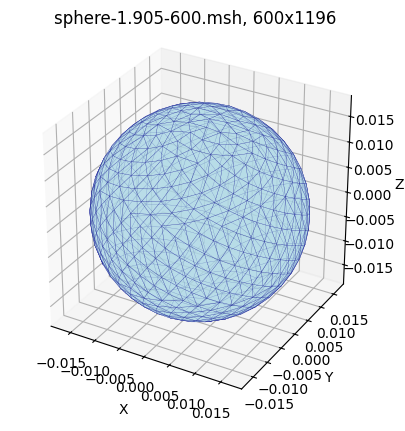

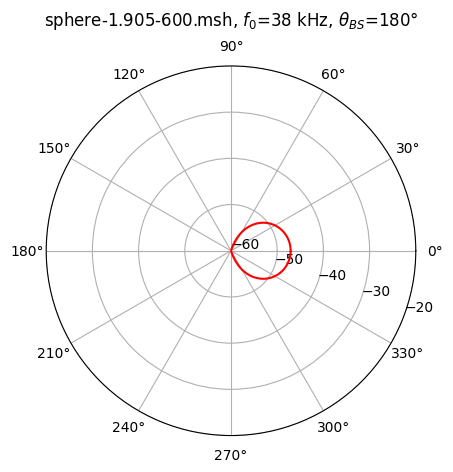

#deg	p_sc
0	0.00441941
1	0.00441835
2	0.00441516
3	0.00440984
4	0.00440241
5	0.00439285
6	0.0043812
7	0.00436746
8	0.00435165
9	0.0043338
10	0.00431391
11	0.00429201
12	0.00426814
13	0.00424231
14	0.00421457
15	0.00418493
16	0.00415345
17	0.00412015
18	0.00408507
19	0.00404826
20	0.00400975
21	0.0039696
22	0.00392785
23	0.00388454
24	0.00383973
25	0.00379347
26	0.0037458
27	0.00369679
28	0.00364649
29	0.00359495
30	0.00354223
31	0.00348839
32	0.00343348
33	0.00337757
34	0.00332071
35	0.00326297
36	0.0032044
37	0.00314507
38	0.00308503
39	0.00302435
40	0.00296309
41	0.00290131
42	0.00283907
43	0.00277643
44	0.00271345
45	0.00265018
46	0.0025867
47	0.00252305
48	0.00245929
49	0.00239548
50	0.00233168
51	0.00226793
52	0.00220431
53	0.00214084
54	0.00207759
55	0.00201462
56	0.00195195
57	0.00188965
58	0.00182776
59	0.00176632
60	0.00170538
61	0.00164498
62	0.00158516
63	0.00152595
64	0.0014674
65	0.00140953
66	0.00135239
67	0.001296
68	0.00124039
69	0.0011856
70	0.00113165
71	0.00107856
72

In [2]:
# !pip install --force-reinstall "numpy<=2.2" scipy bempp-cl matplotlib

import os
repo_name = "mm-bem"
repo_url = f"https://github.com/marmoszy/{repo_name}.git"
if not os.path.exists(repo_name): 
    !git clone {repo_url}
os.chdir(f"{repo_name}/msh")

# MM 21.5.2025: bempp plane wave scattering from fluid sphere
# python3 fluid-bempp.py fname.msh | gnuplot -p polar.gp
#import sys
import bempp_cl as bempp
from bempp_cl.api.operators.boundary import helmholtz as boundary
from bempp_cl.api.operators.potential import helmholtz as potential
from numpy import pi, sin, cos, exp, abs, log10, array, linspace, concatenate
from scipy.sparse.linalg import gmres

# input parameters
fname = 'sphere-1.905-600.msh' #if len(sys.argv)<=1 else sys.argv[1]
th = 0      #if len(sys.argv)<=2 else float(sys.argv[2])
f0 = 38e3   #if len(sys.argv)<=3 else float(sys.argv[3])
c0 = 1480   #if len(sys.argv)<=4 else float(sys.argv[4])
rho0 = 1024 #if len(sys.argv)<=5 else float(sys.argv[5])
c1 = 1540   #if len(sys.argv)<=6 else float(sys.argv[6])
rho1 = 1045 #if len(sys.argv)<=7 else float(sys.argv[7])

# calculated parameters                      
d = array([cos(pi/180*th),sin(pi/180*th),0])# plane wave direction
k0, k1 = 2*pi*f0/c0, 2*pi*f0/c1             # wave numbers

# target mesh and its space
#grid = bempp.api.shapes.sphere(r=0.01905, h=c0/f0/5) # generated mesh
grid = bempp.api.import_grid(fname)
Sp = bempp.api.function_space(grid, "P", 1)

# incident pressure and its normal derivative
@bempp.api.complex_callable
def pinc(x, n, idx, res): res[0] = exp(1j*k0*d.dot(x))
f = bempp.api.GridFunction(Sp, fun=pinc)
@bempp.api.complex_callable
def dpinc(x, n, idx, res): res[0] = 1j*k0*exp(1j*k0*d.dot(x))*d.dot(n)
g = bempp.api.GridFunction(Sp, fun=dpinc)

# surface solution 
A0 = boundary.multitrace_operator(grid, k0) # external Calderon
A1 = boundary.multitrace_operator(grid, k1) # internal Calderon
A1[0,1] *= rho1/rho0; A1[1,0] *= rho0/rho1  # scaled Calderon
A = (A0+A1).strong_form()
fg = concatenate([f.coefficients, g.coefficients])
u, info = gmres(A*A, A*fg)                  # surface solution

# far field solution
r1 = array([[cos(2*pi*i/360),sin(2*pi*i/360),0] for i in range(360)]).T
SL = potential.single_layer(Sp, r1, k0)
DL = potential.double_layer(Sp, r1, k0)
psi = bempp.api.GridFunction(Sp, coefficients=u[: Sp.global_dof_count])
phi = bempp.api.GridFunction(Sp, coefficients=u[Sp.global_dof_count :])
psc = DL * psi - SL * phi                   # far field solution

# plot mesh
v = grid.vertices.T  # Transpose to shape (N, 3)
e = grid.elements.T  # Transpose to shape (M, 3)
n,m = len(v),len(e)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i]) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('lightblue')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v)
ax.set_xlim(v_arr[:, 0].min(), v_arr[:, 0].max())
ax.set_ylim(v_arr[:, 1].min(), v_arr[:, 1].max())
ax.set_zlim(v_arr[:, 2].min(), v_arr[:, 2].max())
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d"%(fname,n,m))
plt.savefig("fluid_bempp_1.svg", format="svg", bbox_inches="tight")
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc[0]])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_{BS}$=%g$\degree$"%(fname,f0/1e3,th+180), va='bottom')
plt.savefig("fluid_bempp_2.svg", format="svg", bbox_inches="tight")
plt.show()

# print
print("#deg\tp_sc")
print("\n".join(["%d\t%g"%(i,abs(psc[0][i])) for i in range(len(psc[0]))]))